# EDA: You Are Bot — кто в диалоге бот?

**Задача.** Для каждого участника короткого диалога предсказать вероятность того, что это бот.
Метрика соревнования — LogLoss, поэтому важны не только порядок, но и калибровка вероятностей.

**Что ищем:** структуру данных, особенности разметки, сигналы, отличающие ботов от людей,
и подводные камни для валидации.

Ноутбук использует тот же код загрузки и признаков, что и пайплайн обучения (`src/youarebot`),
поэтому выводы напрямую переносятся в модель. Графики сохраняются в `reports/figures/`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)

from youarebot.config import load_project_settings
from youarebot.data import data_checksums, data_version, load_dataset
from youarebot.features import MESSAGE_PATTERNS, build_participant_features, numeric_feature_columns
from youarebot.validation import data_quality_report, validate_dataset

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 100)
CLASS_NAMES = {0: "человек", 1: "бот"}
PALETTE = {"человек": "#4C72B0", "бот": "#DD8452"}


def savefig(name: str) -> None:
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Загрузка и контракт данных

In [2]:
settings = load_project_settings()
dataset = validate_dataset(load_dataset(settings.data))  # Pandera-схемы + ссылочная целостность
print("Версия данных:", data_version(data_checksums(settings.data)))

labels = dataset.train_labels
train = dataset.train_messages.merge(labels, on=["dialog_id", "participant_index"])
test = dataset.test_messages
train["класс"] = train["is_bot"].map(CLASS_NAMES)
train["len"] = train["text"].str.len()
test["len"] = test["text"].str.len()
train.head(8)

Версия данных: 6009d4183b37


,dialog_id,message,participant_index,text,is_bot,класс,len
0,0012a424-ae56-414b-a982-04cf24c35229,0,0,"Экономическая ситуация в Зимбабве за последнее время претерпела значительные изменения, и хотя о...",1,бот,191
1,0012a424-ae56-414b-a982-04cf24c35229,1,1,ух ты,0,человек,5
2,0012a424-ae56-414b-a982-04cf24c35229,2,0,"😄 Вот видишь, даже простое «ух ты» может завести интересный разговор! 🤗\n\nДавай продолжим обсуж...",1,бот,160
3,0012a424-ae56-414b-a982-04cf24c35229,3,1,про себя?,0,человек,9
4,0012a424-ae56-414b-a982-04cf24c35229,4,0,"Ну что ж, расскажу! 😊\n\nМеня зовут GigaChat, и я — нейросетевая модель искусственного интеллект...",1,бот,165
5,009a6b25-0289-4845-a392-4025fde96371,0,0,answer,1,бот,6
6,009a6b25-0289-4845-a392-4025fde96371,1,1,Привет,0,человек,6
7,009a6b25-0289-4845-a392-4025fde96371,2,0,answer,1,бот,6


In [3]:
pd.Series(data_quality_report(dataset)).to_frame("значение")

,значение
train_dialogs,1516.000000
train_messages,10490.000000
test_dialogs,379.000000
test_messages,2837.000000
train_bot_share,0.407982
train_dialogs_two_bots,0.000000
train_empty_messages,11.000000
train_messages_over_1000_chars,18.000000


Данные небольшие: около 1.5 тыс. диалогов в train и 0.4 тыс. в test. Схема соблюдается,
у каждого участника train есть метка. Есть единичные пустые реплики и очень длинные вставки.

## 2. Структура диалогов

          count  mean  std  min  25%  50%  75%    max
выборка                                              
test      379.0   7.5  6.8  2.0  5.0  6.0  9.0   87.0
train    1516.0   6.9  5.9  2.0  4.0  6.0  9.0  137.0


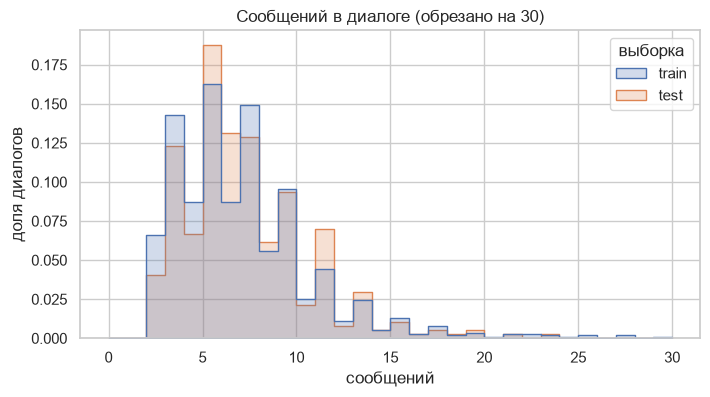

In [4]:
dialog_len = pd.concat([
    train.groupby("dialog_id").size().rename("сообщений").to_frame().assign(выборка="train"),
    test.groupby("dialog_id").size().rename("сообщений").to_frame().assign(выборка="test"),
])
print(dialog_len.groupby("выборка")["сообщений"].describe().round(1))

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=dialog_len, x="сообщений", hue="выборка", stat="density", common_norm=False,
             binwidth=1, binrange=(0, 30), element="step", ax=ax)
ax.set(title="Сообщений в диалоге (обрезано на 30)", xlabel="сообщений", ylabel="доля диалогов")
savefig("dialog_length")
plt.show()

In [5]:
first_speaker = train.loc[train["message"] == 0, "participant_index"].value_counts()
print("Кто пишет первым (participant_index):", first_speaker.to_dict())

Кто пишет первым (participant_index): {0: 1516}


Диалоги короткие: медиана — 6 сообщений, длинный хвост до сотни с лишним.
**Первым всегда пишет участник 0** — роль участника зашита в индекс.

## 3. Целевая переменная и структура пар

Доля ботов среди участников: 0.408
participant_index
0    0.496
1    0.320
Name: P(бот | индекс участника), dtype: float64


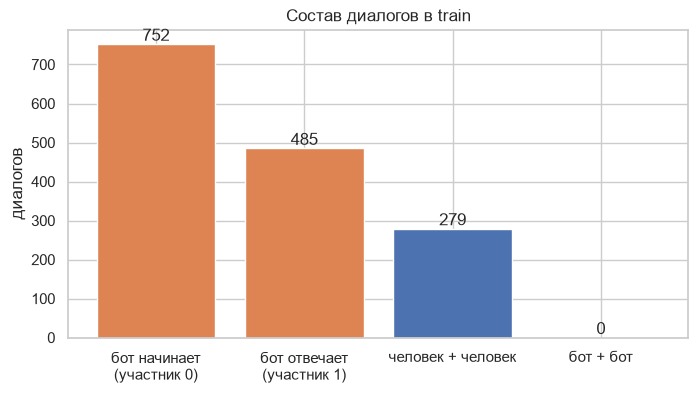

In [6]:
pairs = labels.pivot(index="dialog_id", columns="participant_index", values="is_bot")
kind = np.select(
    [(pairs[0] == 0) & (pairs[1] == 0), (pairs[0] == 1) & (pairs[1] == 0), (pairs[0] == 0) & (pairs[1] == 1)],
    ["человек + человек", "бот начинает\n(участник 0)", "бот отвечает\n(участник 1)"],
    default="бот + бот",
)
kinds = pd.Series(kind).value_counts().reindex(
    ["бот начинает\n(участник 0)", "бот отвечает\n(участник 1)", "человек + человек", "бот + бот"], fill_value=0
)
print("Доля ботов среди участников:", round(labels["is_bot"].mean(), 3))
print(labels.groupby("participant_index")["is_bot"].mean().rename("P(бот | индекс участника)").round(3))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(kinds.index, kinds.values, color=["#DD8452", "#DD8452", "#4C72B0", "#C44E52"])
ax.bar_label(bars)
ax.set(title="Состав диалогов в train", ylabel="диалогов")
savefig("dialog_pairs")
plt.show()

Ключевая структурная особенность: **в диалоге не бывает двух ботов**. 82% диалогов — «человек + бот»,
18% — «человек + человек». Бот чаще оказывается участником 0, то есть начинает диалог
(49.6% против 32% у участника 1).

Что это даёт модели:
* вероятности двух участников одного диалога связаны — признаки собеседника информативны;
* предсказания можно согласовать постобработкой: исход «оба бота» исключается
  (`P(бот) = p(1 - r) / (1 - p·r)`, где `r` — оценка собеседника);
* **валидация только групповая по `dialog_id`**: иначе модель увидит собеседника на обучении.

## 4. Длина и количество реплик

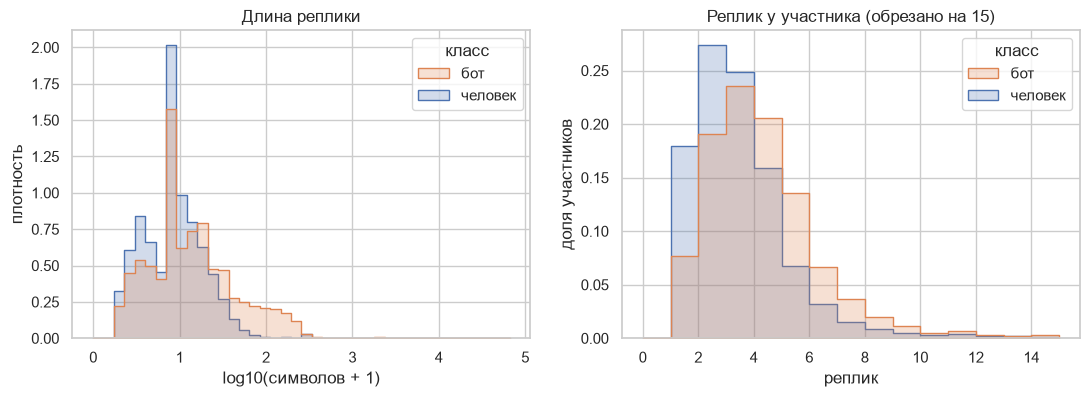

          count  mean    std  min   50%   90%    99%      max
класс                                                        
бот      4928.0  33.5  140.7  1.0  11.0  77.0  238.7   6368.0
человек  5562.0  30.6  958.0  0.0   7.0  22.0   63.0  65826.0


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=train, x=np.log10(train["len"] + 1), hue="класс", stat="density", common_norm=False,
             bins=40, element="step", palette=PALETTE, ax=axes[0])
axes[0].set(title="Длина реплики", xlabel="log10(символов + 1)", ylabel="плотность")

per_participant = train.groupby(["dialog_id", "participant_index", "класс"]).size().rename("реплик").reset_index()
sns.histplot(data=per_participant, x="реплик", hue="класс", stat="density", common_norm=False,
             binwidth=1, binrange=(0, 15), element="step", palette=PALETTE, ax=axes[1])
axes[1].set(title="Реплик у участника (обрезано на 15)", xlabel="реплик", ylabel="доля участников")
savefig("lengths_by_class")
plt.show()
print(train.groupby("класс")["len"].describe(percentiles=[0.5, 0.9, 0.99]).round(1))

In [8]:
longest = train.nlargest(5, "len")[["класс", "len", "text"]].assign(text=lambda f: f["text"].str[:60] + "…")
longest

,класс,len,text
7726,человек,65826,aaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaa…
4184,человек,26809,H̵͑̾͊̈̈́̽͗̓͐̍̆̄͐͊̈́̌̌̾̈̓̉̌͋̐̂͑̄̅̒͂͑̂͆͂͐̿͌̈̀̽̽̇̽͋͌̅͛̽͆̂̓͑͂̋͝͝͠͝…
9348,человек,6368,d̷̊̾͋͂͗̃̈́̐͊̏̓̑͗͛͂̈́́̄̉̈́́̄̿̉̔̔͑̓͊̀̌̈́̉̓̅̂͊̆̓͑̄͒̍̂͋̏̏̾͘͘̚͘̕̕͝͝͝͝…
9349,бот,6368,d̷̊̾͋͂͗̃̈́̐͊̏̓̑͗͛͂̈́́̄̉̈́́̄̿̉̔̔͑̓͊̀̌̈́̉̓̅̂͊̆̓͑̄͒̍̂͋̏̏̾͘͘̚͘̕̕͝͝͝͝…
5758,бот,3782,7์์์์์์์์์์์์์์์์์์์์์์์์์์์์์๋๋๋๋๋๋๋๋๋๋๋๋๋๋๋๋๋๋๋๋๋๋๋๋๋๋๋๋๋๋…


Боты пишут длиннее (медиана 11 символов против 7) и больше реплик. Есть экстремальные вставки
до 65 тыс. символов — для текстовых признаков реплики обрезаются (`max_chars_per_message`),
длины берутся в логарифме.

## 5. Стиль реплик

класс,бот,человек,бот / человек
starts_upper,0.232,0.380,0.613
ends_exclaim,0.026,0.039,0.671
has_other_script,0.004,0.005,0.829
has_latin,0.240,0.287,0.836
has_digit,0.061,0.056,1.087
has_cyrillic,0.745,0.665,1.121
ends_bracket,0.028,0.022,1.265
mentions_bot,0.105,0.082,1.276
ends_question,0.232,0.174,1.332
has_laugh,0.024,0.015,1.528


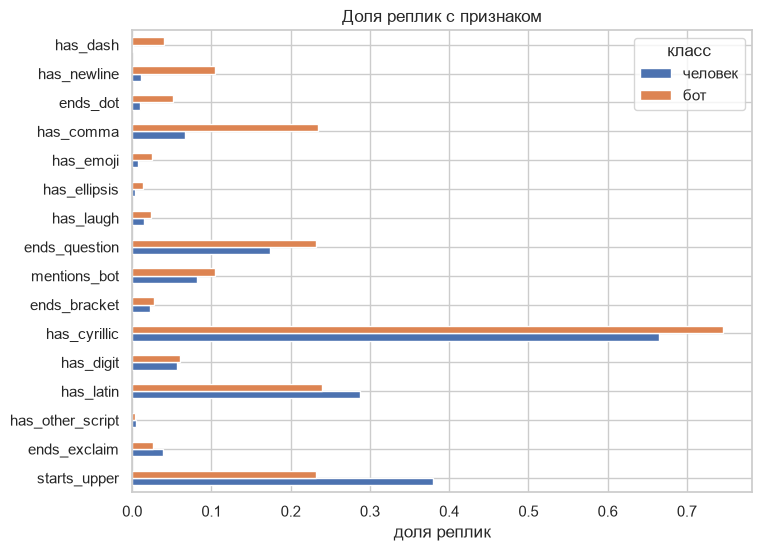

In [9]:
texts = train["text"].astype(object)
style = pd.DataFrame({name: texts.map(lambda t, p=pattern: p.search(t) is not None)
                      for name, pattern in MESSAGE_PATTERNS.items()})
style["класс"] = train["класс"]
shares = style.groupby("класс").mean().T
shares["бот / человек"] = (shares["бот"] + 1e-3) / (shares["человек"] + 1e-3)
shares = shares.sort_values("бот / человек")
display(shares.round(3))

fig, ax = plt.subplots(figsize=(8, 6))
shares[["человек", "бот"]].plot.barh(ax=ax, color=[PALETTE["человек"], PALETTE["бот"]])
ax.set(title="Доля реплик с признаком", xlabel="доля реплик")
savefig("style_flags")
plt.show()

Боты пишут «правильнее»: чаще запятые (23.5% реплик против 6.6%), тире «—» (3.9% против 0.1%),
точка в конце, эмодзи и вопросы. При этом **с заглавной буквы чаще начинают люди** — боты,
похоже, специально имитируют небрежный стиль. Люди чаще спрашивают про бота.

## 6. Эхо и сбои ботов

класс,бот,человек
повторяет реплику собеседника,0.389,0.071
повторяет себя,0.126,0.084
дублирует блок («норм\n\nнорм»),0.116,0.001
спрашивает про бота,0.278,0.204


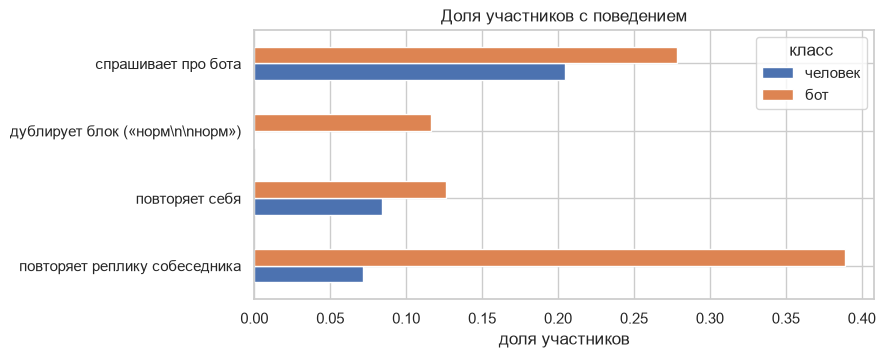

In [10]:
participants = build_participant_features(dataset.train_messages, participants=labels)
participants = participants.merge(labels, on=["dialog_id", "participant_index"])
participants["класс"] = participants["is_bot"].map(CLASS_NAMES)

behaviour = participants.assign(
    **{"повторяет реплику собеседника": participants["is_echo_share"] > 0,
       "повторяет себя": participants["self_repeat_share"] > 0,
       "дублирует блок («норм\\n\\nнорм»)": participants["is_doubled_share"] > 0,
       "спрашивает про бота": participants["mentions_bot_share"] > 0}
).groupby("класс")[["повторяет реплику собеседника", "повторяет себя",
                   "дублирует блок («норм\\n\\nнорм»)", "спрашивает про бота"]].mean().T
display(behaviour.round(3))

fig, ax = plt.subplots(figsize=(8, 3.5))
behaviour[["человек", "бот"]].plot.barh(ax=ax, color=[PALETTE["человек"], PALETTE["бот"]])
ax.set(title="Доля участников с поведением", xlabel="доля участников")
savefig("echo_behaviour")
plt.show()

In [11]:
candidates = participants.query("is_bot == 1 and 4 <= dialog_n_msgs <= 8")
echo_dialog = candidates.sort_values(["is_echo_share", "dialog_id"], ascending=[False, True])["dialog_id"].iloc[0]
example = train.loc[train["dialog_id"] == echo_dialog, ["message", "participant_index", "класс", "text"]]
example

,message,participant_index,класс,text
214,0,0,человек,оппа гангам стайл
215,1,1,бот,оппа гангам стайл
216,2,0,человек,эхобот
217,3,1,бот,эхобот


**Эхо — самый сильный поведенческий сигнал:** простые боты повторяют предыдущую реплику собеседника.
Ещё один артефакт ботов — дублированный блок через пустую строку («норм\n\nнорм»).
Обе особенности не видны мешку слов по одному участнику: нужны признаки взаимодействия
(сравнение с репликами собеседника).

## 7. Язык

In [12]:
lang = np.select(
    [(participants["has_cyrillic_share"] > 0) & (participants["has_latin_share"] == 0),
     (participants["has_latin_share"] > 0) & (participants["has_cyrillic_share"] == 0),
     (participants["has_latin_share"] > 0) & (participants["has_cyrillic_share"] > 0)],
    ["только кириллица", "только латиница", "смешанно"], default="без букв",
)
language = participants.assign(язык=lang).groupby("язык").agg(
    участников=("is_bot", "size"), доля_ботов=("is_bot", "mean")).sort_values("участников", ascending=False)
language.round(3)

,участников,доля_ботов
язык,,
только кириллица,1851,0.396
смешанно,571,0.583
только латиница,560,0.288
без букв,50,0.200


Около четверти реплик — латиницей (английский и другие языки, встречается даже вьетнамский):
символьные n-граммы и признаки письменности (`has_other_script`) полезнее словаря одного языка.

## 8. Какие признаки участника разделяют классы

,ROC AUC одного признака
diff_n_msgs,0.847
is_last_speaker,0.833
msg_share,0.831
other_gets_reply_share,0.825
gets_reply_share,0.193
prev_similarity_mean,0.744
diff_is_echo_share,0.744
prev_similarity_max,0.740
diff_log_len_mean,0.724
other_reply_len_ratio_mean,0.289


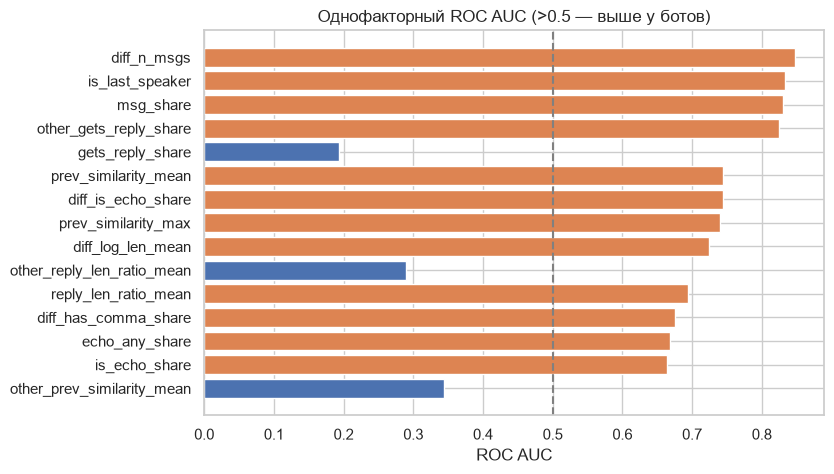

In [13]:
numeric = numeric_feature_columns(participants.drop(columns=["is_bot", "класс"]))
auc = pd.Series({c: roc_auc_score(participants["is_bot"], participants[c]) for c in numeric})
separation = (auc - 0.5).abs().sort_values(ascending=False).head(15)
top = auc[separation.index].rename("ROC AUC одного признака").to_frame()
display(top.round(3))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index[::-1], top.iloc[::-1, 0], color=["#DD8452" if v > 0.5 else "#4C72B0" for v in top.iloc[::-1, 0]])
ax.axvline(0.5, color="grey", linestyle="--")
ax.set(title="Однофакторный ROC AUC (>0.5 — выше у ботов)", xlabel="ROC AUC")
savefig("univariate_auc")
plt.show()

Сильнее всего классы разделяет **структура диалога**: бот отвечает на каждую реплику, поэтому
пишет больше сообщений, чем собеседник, чаще оказывается последним и отвечает почти на каждую
реплику собеседника (95% против 71% у людей). ROC AUC одного такого признака — 0.82–0.85. Дальше идут признаки **взаимодействия** — эхо и сходство с предыдущей репликой
собеседника, — и стиль: запятые, регистр. Модель должна видеть диалог целиком, а не только тексты
одного участника.

⚠️ Структурные признаки посчитаны по **завершённому** диалогу. В онлайн-сценарии (оценка после
каждой реплики) «последним говорящим» всегда будет автор текущей реплики, и эти признаки сместят
прогноз. Для живого чата модель нужно обучать на префиксах диалогов — это план после предзащиты.

## 9. Train и test: есть ли сдвиг

In [14]:
rows = []
for name, a, b in [
    ("длина реплики", train["len"], test["len"]),
    ("сообщений в диалоге", train.groupby("dialog_id").size(), test.groupby("dialog_id").size()),
]:
    ks = stats.ks_2samp(a, b)
    rows.append({"величина": name, "медиана train": a.median(), "медиана test": b.median(),
                 "KS": round(ks.statistic, 3), "p-value": round(ks.pvalue, 3)})
latin = lambda s: s.str.contains("[a-zA-Z]", regex=True).mean()
rows.append({"величина": "доля реплик с латиницей", "медиана train": round(latin(train["text"]), 3),
             "медиана test": round(latin(test["text"]), 3), "KS": None, "p-value": None})
pd.DataFrame(rows)

,величина,медиана train,медиана test,KS,p-value
0,длина реплики,8.000,9.00,0.041,0.001
1,сообщений в диалоге,6.000,6.00,0.069,0.112
2,доля реплик с латиницей,0.265,0.27,NaN,NaN


Распределения train и test близки. KS-тест по длине реплики формально значим (p ≈ 0.001),
но эффект ничтожный: медиана 8 против 9 символов, статистика KS = 0.04. На выборке в 13 тыс.
реплик p-value ловит даже практически несущественный сдвиг. Число сообщений в диалоге
и доля латиницы совпадают. Значит, кросс-валидация на train должна адекватно предсказывать
качество на тесте; проверяем это сабмитами в соревнование.

## 10. Выводы для модели

| Наблюдение | Решение |
|---|---|
| Метка — у участника, а не у диалога; оба участника связаны | признаки участника **и собеседника**, групповая CV по `dialog_id` |
| Двух ботов в диалоге не бывает | постобработка: исключаем исход «оба бота» |
| Участник 0 всегда начинает и чаще бот | `participant_index` — признак |
| Бот отвечает на каждую реплику: пишет больше и последним | доля реплик, «последний говорящий», доля отвеченных реплик, длина ответа; для онлайна — обучение на префиксах |
| Эхо, самоповторы, дублированные блоки | признаки взаимодействия реплик |
| Боты пишут «правильнее», но реже с заглавной | доли пунктуации, регистра, тире, эмодзи |
| Смесь языков, опечатки | символьные n-граммы TF-IDF вместо словаря одного языка |
| Огромные вставки, пустые реплики | обрезка реплик, логарифм длины, контракт данных в Pandera |
| Метрика LogLoss | калиброванные вероятности, контроль калибровки на OOF |

Дальше — эксперименты в MLflow (`run_experiment.sh`): от константы до ансамбля.